# Retail promotions and basket analysis
**Question:** which promotions actually grow a household's spend, and which just give away margin on things people would have bought anyway?

Data: dunnhumby *The Complete Journey* (2017, 2,469 households), loaded into SQLite by `src/load_to_sqlite.py`. All SQL lives in `sql/`; `src/analysis.py` runs it and writes `results/` and `charts/`. This notebook walks through the results.

In [1]:
import json, sqlite3, sys
import pandas as pd
from IPython.display import Image, display
sys.path.insert(0, '../src')
import analysis as A
con = sqlite3.connect('../data/completejourney.db')
F = json.load(open('../results/findings.json'))
pd.set_option('display.precision', 2)

## 1. Data profile
Coverage, missing values and thin-history households (`sql/01_profile.sql`).

In [2]:
display(A.q(con, '01_profile.sql', 'coverage'))
display(A.q(con, '01_profile.sql', 'missing_values'))
A.q(con, '01_profile.sql', 'basket_count_distribution')

,first_day,last_day,households,baskets,stores,products_sold,total_sales
0,2017-01-01,2018-01-01,2469,155848,457,68509,4.60e+06


,column_name,n_missing,n_rows
0,products.department,0,92331
1,products.product_category,540,92331
2,products.product_type,528,92331
3,products.package_size,30586,92331
4,demographics.income,0,801
5,demographics.home_ownership,233,801
6,transactions.zero_or_negative_sales,11226,1469307
7,transactions.product_not_in_catalogue,4836,1469307


,baskets_in_year,households
0,1-4,120
1,5-9,163
2,10-24,487
3,25-49,597
4,50-99,644
5,100+,458


120 households made fewer than 5 trips in the year; they are left out of RFM. `product_type` and `package_size` gaps don't matter here because the analysis works at category level.

## 2. Baseline numbers

Average basket $29.49, 9.4 lines; average week $88,328


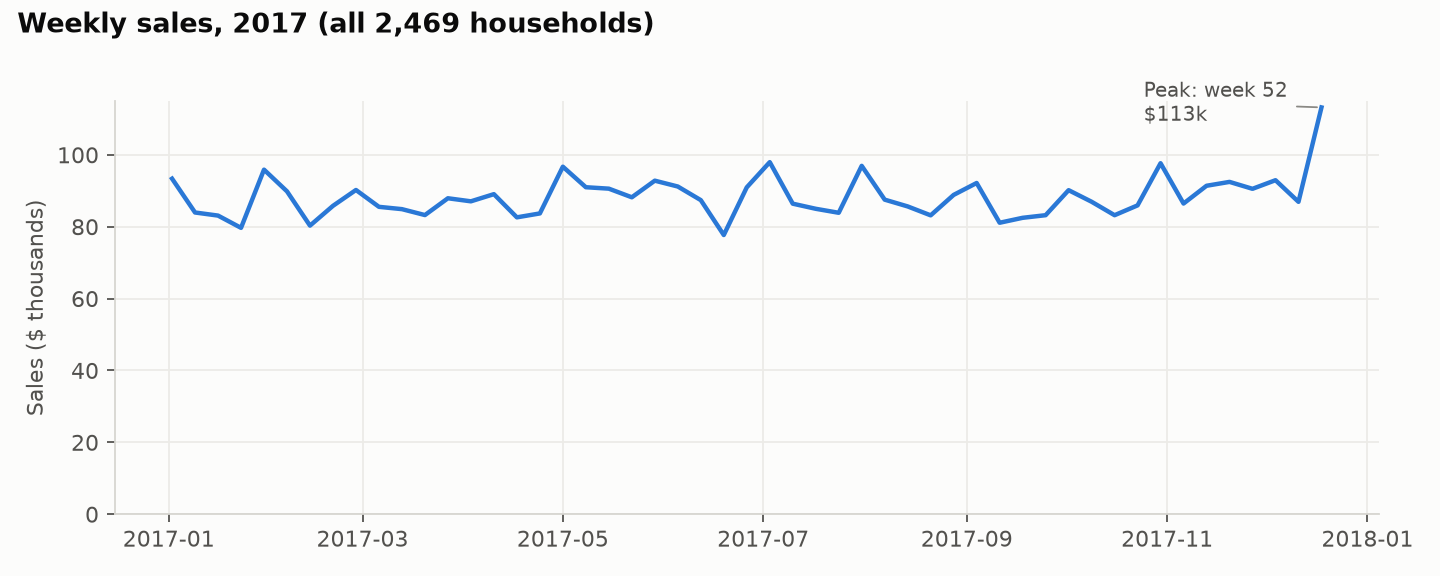

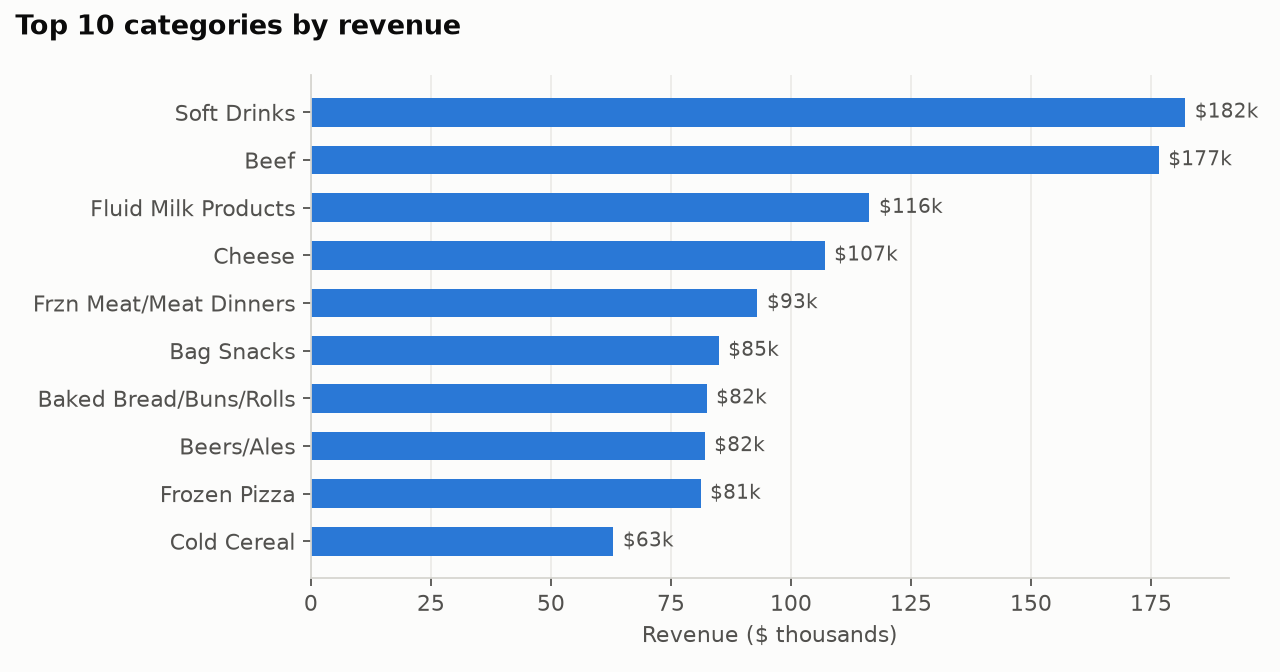

In [3]:
print(f"Average basket ${F['avg_basket_value']:.2f}, {F['avg_lines_per_basket']} lines; average week ${F['avg_weekly_sales']:,.0f}")
display(Image('../charts/01_weekly_sales.png'))
display(Image('../charts/02_top_categories.png'))

## 3. RFM segments

,segment,households,share_of_households,share_of_spend,avg_spend,in_plain_english
0,Champions,463,0.20,0.43,4262.77,"Shop every few days, spend the most, still act..."
1,Loyal regulars,608,0.26,0.28,2113.52,Weekly-ish shoppers with solid spend. The core...
2,At risk,337,0.14,0.16,2186.20,Used to shop often but haven't been seen latel...
3,Lapsed,601,0.26,0.07,558.65,Rare and not recent. Cheapest to let go; low r...
4,New or occasional,187,0.08,0.03,779.29,"Seen recently but rarely. Either new, or a top..."
5,Middle of the road,152,0.07,0.02,714.39,Average on all three measures. Best target for...


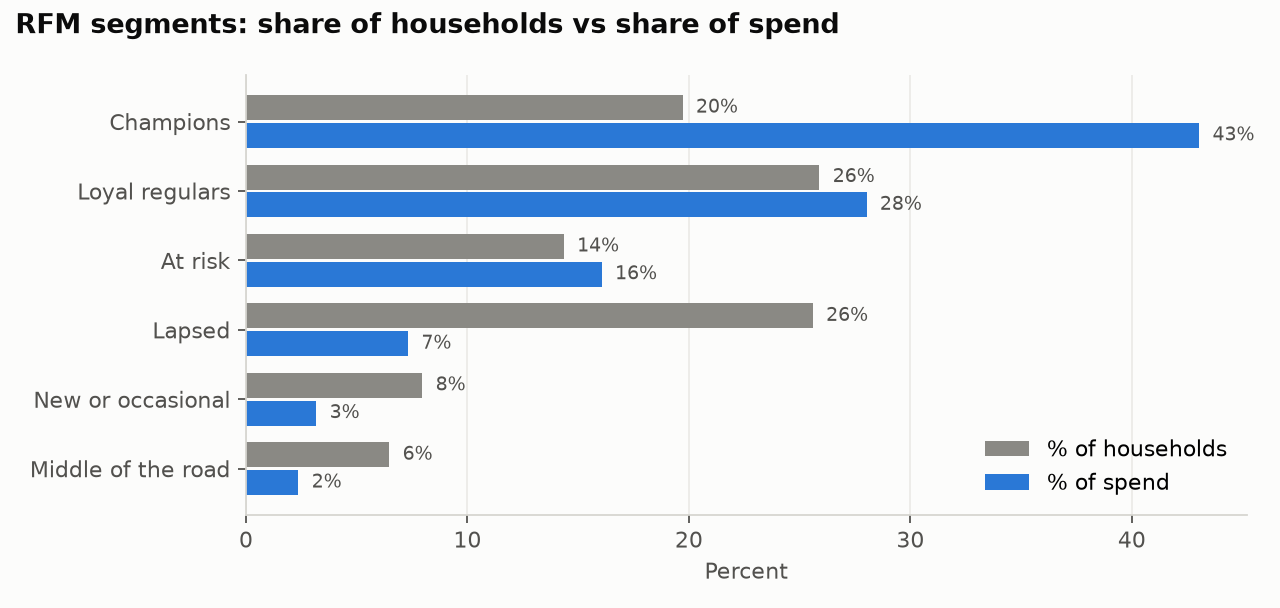

In [4]:
display(pd.read_csv('../results/rfm_segments.csv')[['segment','households','share_of_households','share_of_spend','avg_spend','in_plain_english']])
display(Image('../charts/03_rfm_segments.png'))

## 4. Promotion lift: difference-in-differences
For each campaign, compare each household's weekly spend **during** the campaign with an equal-length window **just before** it, for targeted vs non-targeted households.

Targeted households shop about twice as much as the rest, so a raw comparison is not like for like. The comparison is therefore made **within shopping-intensity deciles** and then averaged. As a check, a **placebo** test runs the same estimate on the two windows *before* each campaign, where the true effect must be zero.

,campaign_id,campaign_type,targeted_hh,did_per_week,ci_low,ci_high,p_value,lift_pct
0,4,Type B,78,6.05,-2.48,14.59,0.16,8.98
1,20,Type C,243,5.09,-0.92,11.10,0.10,6.21
2,21,Type B,64,4.31,-11.31,19.92,0.59,4.73
3,2,Type B,47,2.40,-6.28,11.08,0.59,4.66
4,19,Type B,125,2.00,-4.47,8.47,0.54,2.66
5,18,Type A,1080,1.73,-2.26,5.72,0.40,3.09
6,12,Type B,167,1.41,-4.75,7.58,0.65,1.76
7,14,Type C,222,0.84,-4.51,6.19,0.76,1.00
8,5,Type B,163,0.25,-6.32,6.82,0.94,0.29
9,7,Type B,193,-0.73,-5.39,3.93,0.76,-0.99


,campaign_type,campaigns,avg_did_per_week,avg_lift_pct,significant_campaigns
0,Type A,3.0,-0.53,-0.86,0.0
1,Type B,13.0,-1.65,-2.07,0.0
2,Type C,3.0,2.56,3.14,0.0


Placebo tests significant at 5%: 0 of 19


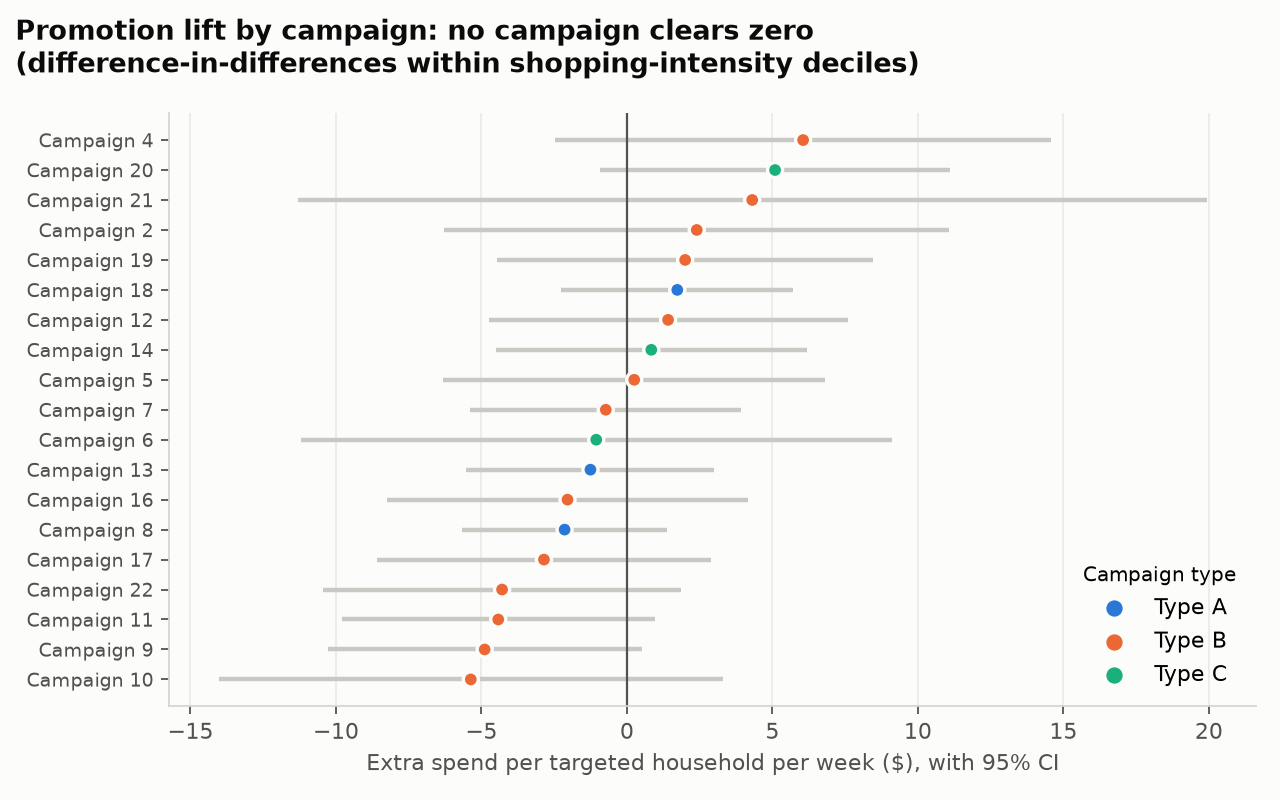

In [5]:
did = pd.read_csv('../results/campaign_did.csv')
display(did[['campaign_id','campaign_type','targeted_hh','did_per_week','ci_low','ci_high','p_value','lift_pct']])
display(pd.read_csv('../results/campaign_did_by_type.csv'))
print('Placebo tests significant at 5%:', F['did']['placebo_significant'], 'of', F['did']['placebo_tests'])
display(Image('../charts/04_campaign_lift.png'))

**Reading:** none of the 19 testable campaigns shows a lift in *total* household spend that is distinguishable from zero. The placebo is also clean (0 of 19 significant), so the method isn't inventing effects. Campaigns may well shift *which* products people buy, but they don't grow the basket.

## 5. Are promotions paying for habits?

15% of coupon uses were on an item the household had bought at full price in the previous 8 weeks


,product_category,coupon_lines,already_buyer_rate,coupon_cost
0,SOFT DRINKS,844,0.29,2223.97
1,CIGARETTES,222,0.41,806.96
2,DIAPERS & DISPOSABLES,287,0.15,481.48
3,AIR CARE,242,0.04,477.96
4,DOG FOODS,254,0.17,476.21
5,FROZEN PIZZA,498,0.14,457.76
6,COLD CEREAL,436,0.19,428.85
7,REFRGRATD DOUGH PRODUCTS,647,0.13,423.39
8,BATH TISSUES,450,0.12,404.75
9,FRZN MEAT/MEAT DINNERS,481,0.17,404.42


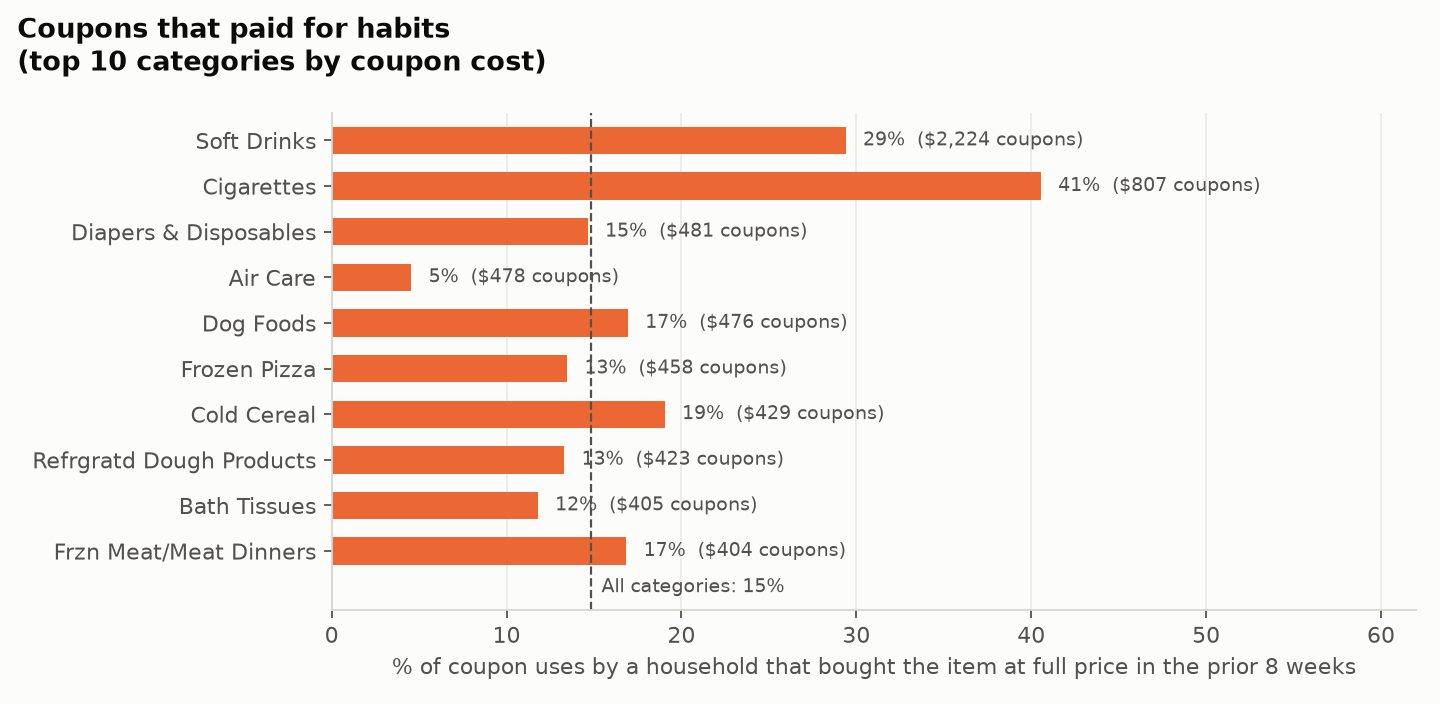

,product_category,revenue,pct_units_on_discount,discount_cost
0,SOFT DRINKS,182124.0,70.6,60932.0
1,BEEF,176615.0,54.8,39135.0
2,CHICKEN,52703.0,72.9,34376.0
3,FLUID MILK PRODUCTS,116361.0,60.3,27904.0
4,CHEESE,107012.0,80.3,26645.0
5,FRZN MEAT/MEAT DINNERS,93024.0,65.6,26495.0
6,BAKED BREAD/BUNS/ROLLS,82430.0,78.6,23205.0
7,ICE CREAM/MILK/SHERBTS,46877.0,80.0,22650.0
8,PORK,50809.0,65.2,22067.0
9,FROZEN PIZZA,81175.0,59.3,16829.0


In [6]:
print(f"{F['coupons']['already_buyer_share']:.0%} of coupon uses were on an item the household had bought at full price in the previous 8 weeks")
display(pd.read_csv('../results/coupon_already_buyer_by_category.csv').head(10))
display(Image('../charts/05_coupon_subsidy.png'))
display(pd.read_csv('../results/category_discount_dependence.csv').head(10))

## 6. Market basket analysis
FP-growth on 137k baskets × 154 categories (categories in at least 1% of baskets).

,antecedents,consequents,support,confidence,lift
0,Beef + Dry Noodles/Pasta,Pasta Sauce,0.01,0.55,11.62
1,Pasta Sauce,Beef + Dry Noodles/Pasta,0.01,0.31,11.62
2,Dry Noodles/Pasta + Soft Drinks,Pasta Sauce,0.01,0.51,10.88
3,Pasta Sauce,Dry Noodles/Pasta + Soft Drinks,0.01,0.25,10.88
4,Beef + Pasta Sauce,Dry Noodles/Pasta,0.01,0.62,10.83
5,Dry Noodles/Pasta,Beef + Pasta Sauce,0.01,0.25,10.83
6,Pasta Sauce,Baked Bread/Buns/Rolls + Dry Noodles/Pasta,0.02,0.32,10.72
7,Baked Bread/Buns/Rolls + Dry Noodles/Pasta,Pasta Sauce,0.02,0.50,10.72
8,Pasta Sauce + Vegetables - Shelf Stable,Dry Noodles/Pasta,0.01,0.60,10.54
9,Deli Meats + Tropical Fruit,Cheeses,0.01,0.49,10.49


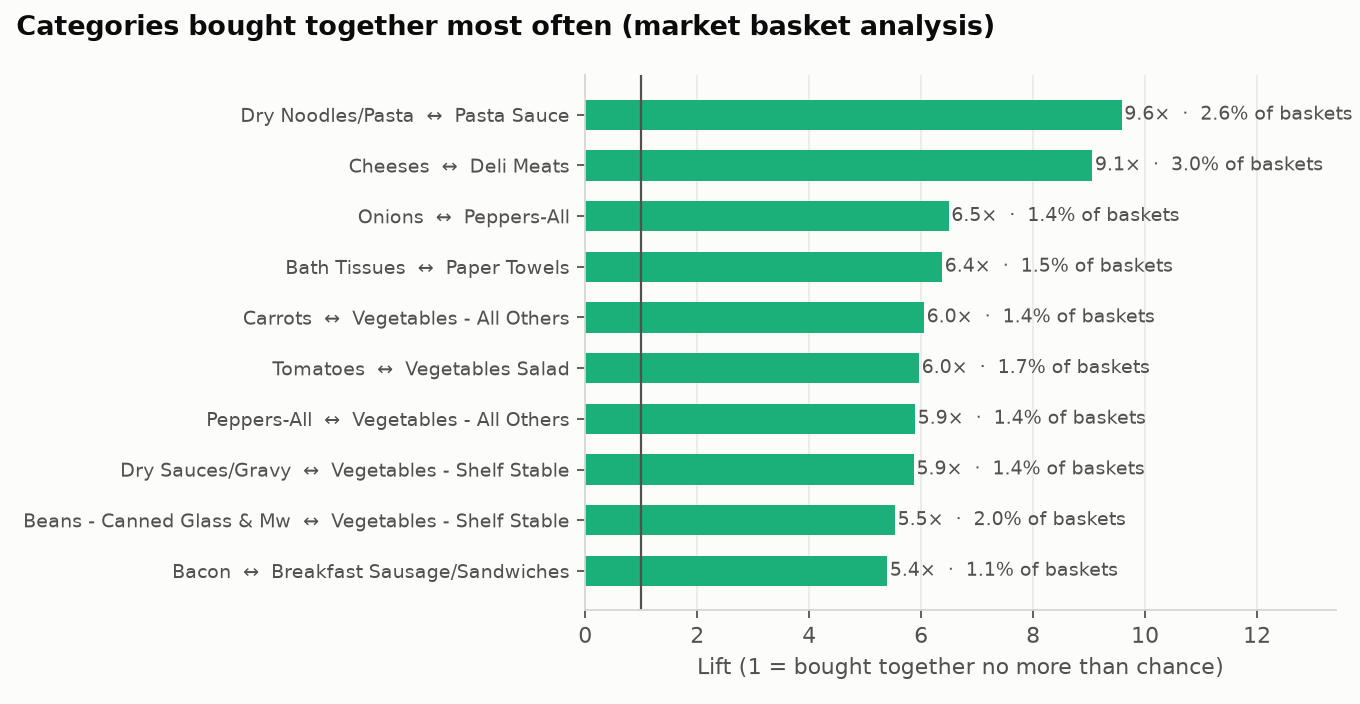

In [7]:
display(pd.read_csv('../results/association_rules.csv').head(15))
display(Image('../charts/06_basket_pairs.png'))

## 7. Recommendations
See the README for the three recommendations, each backed by one number.